In [ ]:
import pandas as pd
#df = pd.read_parquet("../emb_BDs/qu_CommonVoice_embedding/qu_cv.parquet")
#--array demasiado pesado cargar solo colunas especificias
#df = pd.read_parquet("../emb_BDs/qu_siminchik_embedding/qu_iwlst.parquet")
#df = pd.read_parquet("../emb_BDs/qu_Collao_SER/qu_ser.parquet")
df = pd.read_parquet("../emb_BDs/qu_Am&quDataset/qu_AD_embedding.parquet")

In [28]:
#parquets pesados
import pandas as pd

# Carga todo MENOS la columna "array" que es la más pesada
df = pd.read_parquet(
    "../emb_BDs/qu_Am&quDataset/qu_AD_embedding.parquet",
    columns=["id", "path", "sampling_rate", "embedding"]
)

# df = pd.read_parquet("../emb_BDs/qu_30k/dataset_30k_base.parquet")

# Esto debería cargar casi instantáneamente y usar muy poca RAM
print(df.tail())
#print(f"Uso de memoria: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

          id                                               path  \
13936  13936  ../../emb_BDs/qu_Am&quDataset/quechuaDataset_e...   
13937  13937  ../../emb_BDs/qu_Am&quDataset/quechuaDataset_e...   
13938  13938  ../../emb_BDs/qu_Am&quDataset/quechuaDataset_e...   
13939  13939  ../../emb_BDs/qu_Am&quDataset/quechuaDataset_e...   
13940  13940  ../../emb_BDs/qu_Am&quDataset/quechuaDataset_e...   

       sampling_rate                                          embedding  
13936          16000  [0.09086703509092331, -0.14302393794059753, -0...  
13937          16000  [-0.39913761615753174, -0.15088030695915222, -...  
13938          16000  [-0.3441741466522217, -0.13315828144550323, -0...  
13939          16000  [-0.4517871141433716, -0.19180932641029358, -0...  
13940          16000  [0.25141724944114685, -0.20224152505397797, -0...  


In [26]:
import pyarrow.parquet as pq

pf = pq.ParquetFile("../emb_BDs/qu_CommonVoice_embedding/qu_cv.parquet")

for field in pf.schema:
    print(field.name)

id
path
sampling_rate
element
element


In [33]:
print(df['path'].head())

0    ../../emb_BDs/qu_Am&quDataset/quAmericasNLP_em...
1    ../../emb_BDs/qu_Am&quDataset/quAmericasNLP_em...
2    ../../emb_BDs/qu_Am&quDataset/quAmericasNLP_em...
3    ../../emb_BDs/qu_Am&quDataset/quAmericasNLP_em...
4    ../../emb_BDs/qu_Am&quDataset/quAmericasNLP_em...
Name: path, dtype: object


In [30]:
print(df.columns)
print(df.count())
print(df.head())
print(df.dtypes)
print(type(df['embedding'][0]))
print(len(df['embedding'][0]))
print(df["embedding"].iloc[0], type(df["embedding"].iloc[0][0]))



Index(['id', 'path', 'sampling_rate', 'embedding'], dtype='object')
id               13941
path             13941
sampling_rate    13941
embedding        13941
dtype: int64
   id                                               path  sampling_rate  \
0   0  ../../emb_BDs/qu_Am&quDataset/quAmericasNLP_em...          16000   
1   1  ../../emb_BDs/qu_Am&quDataset/quAmericasNLP_em...          16000   
2   2  ../../emb_BDs/qu_Am&quDataset/quAmericasNLP_em...          16000   
3   3  ../../emb_BDs/qu_Am&quDataset/quAmericasNLP_em...          16000   
4   4  ../../emb_BDs/qu_Am&quDataset/quAmericasNLP_em...          16000   

                                           embedding  
0  [-0.15150709450244904, -0.1999662071466446, -0...  
1  [-0.28033438324928284, -0.18283331394195557, -...  
2  [0.13933859765529633, -0.22331549227237701, -0...  
3  [0.11813142895698547, -0.1417997181415558, -0....  
4  [0.20301827788352966, -0.2324184775352478, -0....  
id                int64
path             objec

In [14]:
import pandas as pd

POOL_PARQUETS = [
    ("CommonVoice", "../emb_BDs/qu_CommonVoice_embedding/qu_cv.parquet"),
    ("Siminchik", "../emb_BDs/qu_siminchik_embedding/qu_iwlst.parquet"),
    ("QuechuaSER", "../emb_BDs/qu_Collao_SER/qu_ser.parquet"),
    ("AmericasNLP", "../emb_BDs/qu_Am&quDataset/qu_AD_embedding.parquet"),
]

dfs = []

for source, path in POOL_PARQUETS:
    print(f"Leyendo {source}")

    df = pd.read_parquet(
        path,
        columns=["id", "embedding"]  # conserva id original
    )

    df["source_dataset"] = source  # trazabilidad
    dfs.append(df)

df_all = pd.concat(dfs, ignore_index=True)

print("Total embeddings:", len(df_all))

df_all.to_parquet(
    "dataset_30k_base.parquet",
    index=False
)

print("dataset_30k_base.parquet creado")

Leyendo CommonVoice
Leyendo Siminchik
Leyendo QuechuaSER
Leyendo AmericasNLP
Total embeddings: 35085
dataset_30k_base.parquet creado


In [ ]:
# import pandas as pd
# import numpy as np
# import faiss

# # 1. Cargar dataset parquet
# #df = pd.read_parquet("dataset_completo.parquet")

# # Extraer solo id y df_test['emb']
# df_train = df[["id", "embedding"]].copy()
# df_train = df_train.rename(columns={"embedding": "emb"})

# # 2. Split train / test
# # por ejemplo 90% train, 10% test
# df_test = df_train.sample(frac=0.1, random_state=42)
# df_train_final = df_train.drop(df_test.index)

# # 3. Calcular ground truth con FAISS
# emb_train = np.stack(df_train_final["emb"].values).astype("float32")
# emb_test = np.stack(df_test["emb"].values).astype("float32")

# index = faiss.IndexFlatL2(emb_train.shape[1])  # índice exacto L2
# index.add(emb_train)

# k = 10  # número de vecinos que pide el benchmark
# distances, indices = index.search(emb_test, k)

# # Construir groundtruth DataFrame
# df_groundtruth = pd.DataFrame({
#     "id": df_test["id"].values,
#     "neighbors_id": indices.tolist()
# })

# # 4. Guardar archivos
# df_train_final.to_parquet("train.parquet", index=False)
# df_test.to_parquet("test.parquet", index=False)
# df_groundtruth.to_parquet("groundtruth.parquet", index=False)

# print(" Archivos listos: train.parquet, test.parquet, groundtruth.parquet")


 Archivos listos: train.parquet, test.parquet, groundtruth.parquet


In [ ]:
import pandas as pd
import numpy as np
import faiss
import os

OUTPUT_DIR = "30k_dataset"
TEST_FRAC = 0.1   # 10% para test
TOP_K = 10     # para ground truth

# # ================================
# # 0. CONFIG
# # ================================
# INPUT_PARQUET = "dataset_completo.parquet"
# OUTPUT_DIR = "vdbbench_ready"
# TEST_FRAC = 0.1   # 10% para test
# TOP_K = 100       # para ground truth

# os.makedirs(OUTPUT_DIR, exist_ok=True)

# # ================================
# # 1. Cargar dataset original
# # ================================
# df = pd.read_parquet(INPUT_PARQUET)

# El dataset debe tener id y embedding
if "id" not in df.columns or "embedding" not in df.columns:
    raise ValueError("El parquet debe contener columnas: id, embedding")

# Renombrar a formato oficial
df = df.rename(columns={"embedding": "emb"})

# ================================
# 2. Convertir embeddings a float32
# ================================
df["emb"] = df["emb"].apply(lambda x: np.asarray(x, dtype=np.float32))

dim = len(df["emb"].iloc[0])
print(f"Dimensionalidad: {dim}")

# ================================
# 3. Split train / test
# ================================
df_test = df.sample(frac=TEST_FRAC, random_state=42)
df_train = df.drop(df_test.index)

# ================================
# 4. Reset IDs a formato oficial
# ================================
df_train = df_train.reset_index(drop=True)
df_train["id"] = df_train.index

df_test = df_test.reset_index(drop=True)
df_test["id"] = df_test.index

# ================================
# 5. Guardar train/test
# ================================
df_train_out = df_train[["id", "emb"]]
df_test_out = df_test[["id", "emb"]]

df_train_out.to_parquet(f"{OUTPUT_DIR}/train.parquet", index=False)
df_test_out.to_parquet(f"{OUTPUT_DIR}/test.parquet", index=False)

print("train.parquet y test.parquet listos.")

# ================================
# 6. Calcular ground truth con FAISS
# ================================
X_train = np.vstack(df_train_out["emb"].tolist()).astype("float32")
X_test = np.vstack(df_test_out["emb"].tolist()).astype("float32")

index = faiss.IndexFlatL2(dim)
index.add(X_train)
dist, neighbors = index.search(X_test, TOP_K)

# ================================
# 7. Guardar ground truth oficial
# ================================
df_neighbors = pd.DataFrame({
    "id": df_test_out["id"],
    "neighbors_id": neighbors.tolist()
})

df_neighbors.to_parquet(f"{OUTPUT_DIR}/neighbors.parquet", index=False)

print("neighbors.parquet generado correctamente.")
print("Dataset listo para VDBBench.")

Dimensionalidad: 1024
train.parquet y test.parquet listos.
neighbors.parquet generado correctamente.
Dataset listo para VDBBench.


In [ ]:
df_test = pd.read_parquet("cv_dataset_2/test.parquet")
df_train = pd.read_parquet("cv_dataset_2/train.parquet")
df_groundtruth = pd.read_parquet("cv_dataset_2/neighbors.parquet")

In [4]:
import numpy as np
print("=== Shapes ===")
print("train:", df_train.shape)
print("test:", df_test.shape)
print("groundtruth:", df_groundtruth.shape)

print("\n=== Columnas ===")
print("train:", df_train.columns)
print("test:", df_test.columns)
print("groundtruth:", df_groundtruth.columns)

print("\n=== Tipos ===")
print(df_train.dtypes)
print(df_test.dtypes)
print(df_groundtruth.dtypes)

# --- Revisar embeddings ---
print("\n=== Shapes de embeddings ===")
print("train emb0:", np.array(df_train.iloc[0].emb).shape)
print("test emb0:", np.array(df_test.iloc[0].emb).shape)
print("tipo:",type(df_train["emb"].iloc[0][0]))

# --- Validar groundtruth ===
print("\n=== Validación de groundtruth ===")
print("IDs test únicos:", len(df_test["id"]))
print("IDs gt únicos:", len(df_groundtruth["id"]))

# Validar que todos los IDs del groundtruth estén en test
print("GT tiene IDs no presentes en test:",
      set(df_groundtruth["id"]) - set(df_test["id"]))

# Validar que los neighbors no excedan el rango del train
all_neighbors = np.array(df_groundtruth["neighbors_id"].tolist())
max_neighbor = all_neighbors.max()
min_neighbor = all_neighbors.min()

print("Rango neighbors:", min_neighbor, "→", max_neighbor)
print("Debe ser < len(train):", len(df_train))




=== Shapes ===
train: (1121, 2)
test: (124, 2)
groundtruth: (124, 2)

=== Columnas ===
train: Index(['id', 'emb'], dtype='object')
test: Index(['id', 'emb'], dtype='object')
groundtruth: Index(['id', 'neighbors_id'], dtype='object')

=== Tipos ===
id      int64
emb    object
dtype: object
id      int64
emb    object
dtype: object
id               int64
neighbors_id    object
dtype: object

=== Shapes de embeddings ===
train emb0: (1024,)
test emb0: (1024,)
tipo: <class 'numpy.float32'>

=== Validación de groundtruth ===
IDs test únicos: 124
IDs gt únicos: 124
GT tiene IDs no presentes en test: set()
Rango neighbors: 8 → 1118
Debe ser < len(train): 1121


In [12]:
import pyarrow.parquet as pq

print(pq.read_schema("cv_dataset_2/train.parquet"))
print(pq.read_schema("cv_dataset_2/test.parquet"))
print(pq.read_schema("cv_dataset_2/neighbors.parquet"))



id: int64
emb: list<element: float>
  child 0, element: float
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 288
id: int64
emb: list<element: float>
  child 0, element: float
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 288
id: int64
neighbors_id: list<element: int64>
  child 0, element: int64
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 304


In [5]:
print(df_train['id'].head())
print(df_train.index[:10])

0    0
1    1
2    2
3    3
4    4
Name: id, dtype: int64
RangeIndex(start=0, stop=10, step=1)


In [6]:
import numpy as np
len(df_train["emb"].iloc[0])

1024

In [7]:
print(df_train.count())

id     12547
emb    12547
dtype: int64


In [5]:
df_train

,id,emb
0,0,"[0.13140184, -0.18825786, -0.26128256, -0.2206..."
1,1,"[0.05655635, -0.21118686, -0.17317142, -0.2607..."
2,2,"[-0.09938188, -0.17371204, -0.15271568, -0.223..."
3,3,"[0.14684851, -0.20218278, -0.235803, -0.188448..."
4,4,"[0.12903291, -0.2184733, -0.18350331, -0.24931..."
...,...,...
1116,1116,"[0.10182644, -0.17467687, -0.25225803, -0.2551..."
1117,1117,"[0.16625915, -0.19924077, -0.07357537, -0.2323..."
1118,1118,"[0.19606578, -0.18808143, -0.14952537, -0.2114..."
1119,1119,"[0.1753335, -0.23610367, -0.2293221, -0.263327..."


In [6]:
df_test

,id,emb
0,0,"[0.002592048, -0.17339794, -0.19194613, -0.297..."
1,1,"[0.057923302, -0.21472703, -0.2706291, -0.2576..."
2,2,"[0.13317443, -0.22313745, -0.24321614, -0.2307..."
3,3,"[0.0590243, -0.20756762, -0.22671208, -0.27740..."
4,4,"[0.10660407, -0.21600841, -0.20343266, -0.2376..."
...,...,...
119,119,"[0.12100233, -0.2370245, -0.25435966, -0.24982..."
120,120,"[0.22739865, -0.16840582, -0.1783102, -0.16577..."
121,121,"[0.16558008, -0.27530065, -0.12810305, -0.3205..."
122,122,"[0.009243901, -0.25425723, -0.16500892, -0.254..."


In [7]:
df_groundtruth

,id,neighbors_id
0,0,"[335, 648, 345, 243, 286, 155, 224, 358, 902, ..."
1,1,"[205, 392, 243, 369, 161, 249, 356, 83, 475, 445]"
2,2,"[1082, 393, 116, 896, 483, 196, 842, 370, 164,..."
3,3,"[89, 185, 244, 569, 214, 442, 346, 62, 305, 44]"
4,4,"[140, 250, 442, 55, 102, 225, 62, 164, 289, 320]"
...,...,...
119,119,"[250, 245, 697, 93, 389, 140, 130, 55, 338, 1064]"
120,120,"[1071, 954, 63, 964, 24, 1089, 427, 963, 32, 31]"
121,121,"[55, 308, 245, 139, 178, 228, 201, 102, 127, 1..."
122,122,"[187, 59, 201, 244, 62, 109, 224, 103, 222, 374]"


In [29]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

emb_matrix = np.vstack(df_train["emb"].to_numpy())
idx = np.random.choice(len(emb_matrix), size=1000, replace=False)
subset = emb_matrix[idx]

# Muestra 1000 embeddings aleatorios
#subset = df_train[np.random.choice(len(df_train), size=1000, replace=False)]
sims = cosine_similarity(subset)

# Ignorar diagonal
mean_off_diag = (np.sum(sims) - np.trace(sims)) / (sims.size - len(subset))
std_off_diag = np.std(sims[np.triu_indices_from(sims, k=1)])

print(f"Media entre embeddings distintos: {mean_off_diag:.4f}")
print(f"Desviación estándar: {std_off_diag:.4f}")

Media entre embeddings distintos: 0.8191
Desviación estándar: 0.1662


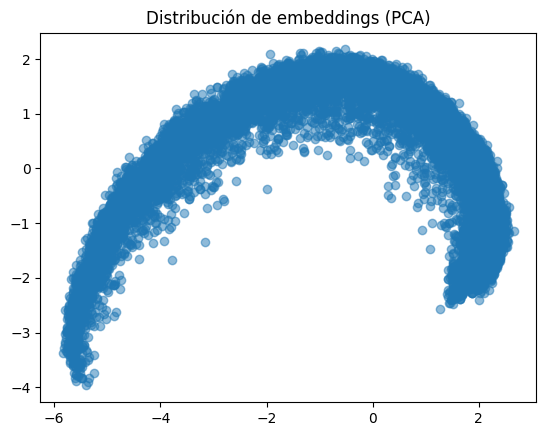

[0.6265349  0.14944056]
0.77597547


In [30]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

emb_matrix = np.vstack(df_train["emb"].to_numpy())

pca = PCA(n_components=2)
proj = pca.fit_transform(emb_matrix)

plt.scatter(proj[:,0], proj[:,1], alpha=0.5)
plt.title("Distribución de embeddings (PCA)")
plt.show()
print(pca.explained_variance_ratio_)
print(pca.explained_variance_ratio_.sum())


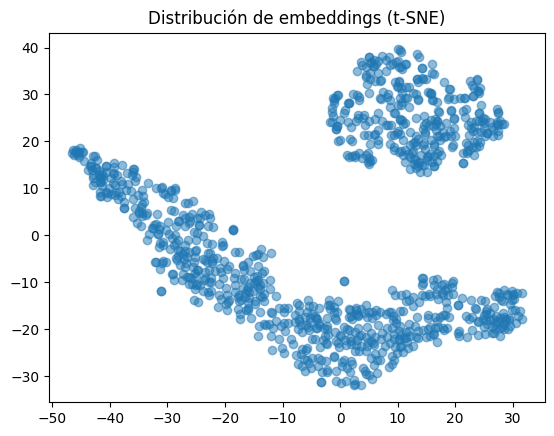

In [31]:
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
proj_tsne = tsne.fit_transform(emb_matrix[:1000])
plt.scatter(proj_tsne[:,0], proj_tsne[:,1], alpha=0.5)
plt.title("Distribución de embeddings (t-SNE)")
plt.show()

In [9]:
import chromadb
client = chromadb.HttpClient(host="localhost", port=8000)
print("heartbeat:", client.heartbeat())

heartbeat: 1772751193160603242


In [1]:
#verificar chroma
import chromadb

# Conectarse a tu Docker
client = chromadb.HttpClient(host='localhost', port=8000)

# Listar todas las colecciones que creó vectordb-bench
colecciones = client.list_collections()

print(f"Se encontraron {len(colecciones)} colecciones.")

for col in colecciones:
    print(f"\n--- Colección: {col.name} ---")
    # AQUÍ está la configuración del índice HNSW
    print("Metadatos (Configuración HNSW):") 
    print(col.configuration)

Se encontraron 1 colecciones.

--- Colección: VectorDBBenchCollection ---
Metadatos (Configuración HNSW):
{'hnsw': {'space': 'l2', 'ef_construction': 128, 'ef_search': 100, 'max_neighbors': 16, 'resize_factor': 1.2, 'sync_threshold': 1000}, 'spann': None, 'embedding_function': <chromadb.utils.embedding_functions.DefaultEmbeddingFunction object at 0x00000148F454E210>}


In [5]:
import chromadb
client = chromadb.HttpClient(host="localhost", port=8000)

cols = client.list_collections()
print("Colecciones:", [c.name for c in cols])

for c in cols:
    col = client.get_collection(c.name)
    cfg = col.configuration.get("hnsw", {})
    print(f"{c.name}: count={col.count()} efc={cfg.get('ef_construction')} M={cfg.get('max_neighbors')} efs={cfg.get('ef_search')}")

Colecciones: ['VectorDBBenchCollection']
VectorDBBenchCollection: count=31577 efc=128 M=16 efs=100


In [4]:
import chromadb

client = chromadb.HttpClient(host="localhost", port=8000)

cols = client.list_collections()

print("Colecciones antes:", [c.name for c in cols])

for c in cols:
    try:
        client.delete_collection(c.name)
        print("Deleted:", c.name)
    except Exception as e:
        print("Error deleting", c.name, e)

print("Colecciones después:", client.list_collections())

Colecciones antes: []
Colecciones después: []


In [8]:
import chromadb

client = chromadb.HttpClient(host='localhost', port=8000)

# Obtener la colección sospechosa
try:
    col = client.get_collection(name="VectorDBBenchCollection")
    print(f"Cantidad de vectores: {col.count()}")
    
    # Ver los primeros 3 documentos para identificar el contenido
    datos = col.peek(limit=3)
    print("Contenido de muestra:", datos)
    
except Exception as e:
    print(f"Error: {e}")

Cantidad de vectores: 31577
Contenido de muestra: {'ids': ['0', '1', '2'], 'embeddings': array([[ 0.13140184, -0.18825786, -0.26128256, ..., -0.09362876,
        -0.00226057,  0.07123984],
       [ 0.05655635, -0.21118686, -0.17317142, ..., -0.05731382,
        -0.0146834 ,  0.11608186],
       [-0.09938188, -0.17371204, -0.15271568, ..., -0.09219084,
        -0.04761878,  0.16835539]], shape=(3, 1024)), 'metadatas': [{'index': 0}, {'index': 1}, {'index': 2}], 'documents': [None, None, None], 'data': None, 'uris': None, 'included': ['metadatas', 'documents', 'embeddings']}


In [3]:
import pandas as pd
df = pd.read_parquet("../emb_BDs/quNLPAmericas_embedding/qu_NLP2022.parquet")

In [28]:
df.iloc[0]
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 823 entries, 0 to 822
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id              823 non-null    int64 
 1   path            823 non-null    object
 2   sampling_rate   823 non-null    int64 
 3   audio_original  823 non-null    object
 4   target_raw      823 non-null    object
 5   source_raw      823 non-null    object
 6   embedding       823 non-null    object
dtypes: int64(2), object(5)
memory usage: 45.1+ KB


In [29]:
import pandas as pd
import numpy as np
import faiss
import os

# CONFIGURACIÓN DE RUTAS
#-- INPUT_PARQUET = "dataset_completo.parquet"
DIR_BENCHMARK = "823_dataset"  # Solo para el benchmark
DIR_METADATA = "823_dataset_metadata"    # Solo para tu análisis de tesis

os.makedirs(DIR_BENCHMARK, exist_ok=True)
os.makedirs(DIR_METADATA, exist_ok=True)

# 1. Cargar dataset
#-- df = pd.read_parquet(INPUT_PARQUET)

# 2. Split Train/Test (fijamos random_state=42 para consistencia total)
df_test_raw = df.sample(frac=0.1, random_state=42)
df_train_raw = df.drop(df_test_raw.index)

def export_data(df_raw, name):
    # Reset index para generar el ID correlativo que usa el benchmark
    df_clean = df_raw.reset_index(drop=True)
    df_clean["id"] = df_clean.index
    
    # --- ARCHIVO PARA BENCHMARK (ID + EMB) ---
    df_bench = pd.DataFrame({
        "id": df_clean["id"],
        "emb": df_clean["embedding"].apply(lambda x: np.asarray(x, dtype=np.float32))
    })
    df_bench.to_parquet(f"{DIR_BENCHMARK}/{name}.parquet", index=False)
    
    # --- ARCHIVO PARA ANÁLISIS (ID + METADATA COMPLETA) ---
    # Guardamos todo menos el embedding para no ocupar espacio innecesario
    df_map = df_clean.drop(columns=["embedding"]) 
    df_map.to_parquet(f"{DIR_METADATA}/map_{name}.parquet", index=False)
    
    return df_bench

print("Generando archivos...")
df_train_bench = export_data(df_train_raw, "train")
df_test_bench = export_data(df_test_raw, "test")

# 3. Calcular Ground Truth (Vecinos Reales)
print("Calculando Ground Truth con FAISS...")
X_train = np.vstack(df_train_bench["emb"].tolist()).astype("float32")
X_test = np.vstack(df_test_bench["emb"].tolist()).astype("float32")

index = faiss.IndexFlatL2(X_train.shape[1])
index.add(X_train)
dist, neighbors = index.search(X_test, 100) # Buscamos top 100

# 4. Guardar Ground Truth en la carpeta del Benchmark
df_neighbors = pd.DataFrame({
    "id": df_test_bench["id"],
    "neighbors_id": neighbors.tolist()
})
df_neighbors.to_parquet(f"{DIR_BENCHMARK}/neighbors.parquet", index=False)

print(f"\n✅ LISTO:")
print(f"- Carpeta '{DIR_BENCHMARK}': Contiene train, test y neighbors (Úsalos en el benchmark).")
print(f"- Carpeta '{DIR_METADATA}': Contiene map_train y map_test (Úsalos para tu análisis).")

Generando archivos...
Calculando Ground Truth con FAISS...

✅ LISTO:
- Carpeta '823_dataset': Contiene train, test y neighbors (Úsalos en el benchmark).
- Carpeta '823_dataset_metadata': Contiene map_train y map_test (Úsalos para tu análisis).


In [18]:
import pandas as pd
# Cargar los mapas y los vecinos reales
map_test = pd.read_parquet("823_dataset_metadata/map_test.parquet")
map_train = pd.read_parquet("823_dataset_metadata/map_train.parquet")
gt = pd.read_parquet("823_dataset/neighbors.parquet")
# --- gt = pd.read_parquet("vdbbench_ready/neighbors.parquet")



In [19]:
map_test.head(5)
map_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82 entries, 0 to 81
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id              82 non-null     int64 
 1   path            82 non-null     object
 2   sampling_rate   82 non-null     int64 
 3   audio_original  82 non-null     object
 4   target_raw      82 non-null     object
 5   source_raw      82 non-null     object
dtypes: int64(2), object(4)
memory usage: 4.0+ KB


In [20]:
map_train.head(5)
map_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 741 entries, 0 to 740
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id              741 non-null    int64 
 1   path            741 non-null    object
 2   sampling_rate   741 non-null    int64 
 3   audio_original  741 non-null    object
 4   target_raw      741 non-null    object
 5   source_raw      741 non-null    object
dtypes: int64(2), object(4)
memory usage: 34.9+ KB


In [36]:
gt

,id,neighbors_id
0,0,"[542, 549, 682, 494, 681, 739, 593, 531, 699, ..."
1,1,"[134, 103, 255, 126, 128, 129, 225, 40, 88, 14..."
2,2,"[220, 93, 235, 389, 21, 117, 314, 324, 143, 69..."
3,3,"[55, 400, 182, 181, 423, 222, 56, 334, 236, 18..."
4,4,"[51, 237, 216, 151, 187, 99, 325, 68, 153, 74,..."
...,...,...
77,77,"[98, 41, 254, 64, 119, 42, 6, 79, 172, 192, 38..."
78,78,"[345, 368, 254, 340, 291, 192, 305, 189, 280, ..."
79,79,"[253, 111, 75, 215, 384, 238, 222, 240, 56, 18..."
80,80,"[479, 525, 507, 498, 508, 712, 456, 711, 723, ..."


In [57]:
# Supongamos que el test_id 10 tuvo mal desempeño
test_id = 10
ids_vecinos_reales = df_neighbors.iloc[test_id]["neighbors_id"]

# Ver qué audio era el que buscábamos
print(f"Buscando audio: {map_test.iloc[test_id]['audio_original']}")
print(f"Texto en Quechua: {map_test.iloc[test_id]['source_raw']}")

print("\nResultados esperados (lo que el motor debió encontrar):")
for n_id in ids_vecinos_reales[:5]:
    print(f"- {map_train.iloc[n_id]['audio_original']} | {map_train.iloc[n_id]['source_raw']}")

Buscando audio: quechua000821.wav
Texto en Quechua: allintachu raraskanku autoridaqkuna kapachiypi ancha llakikuy turachay kachkan hayqami kay aparikusqanqa kay chaqwari maytaq arí turachanchik ichapapas ñañachya nely qam tarpuriwaq chayllarumanta chinkarirqapun kay waqakuy tawa tutamanta kimsa chunka huyniyuq yupayña puriykusun rimanaq wasi rimayninkunawan

Resultados esperados (lo que el motor debió encontrar):
- quechua000820.wav | apachikamanta waqamuchkaki allin chikaqa wawqiy willarikuychu napaykuchu karichkan comunidad san cristobalmanta waqamuchkaki qayna karqan huk reunión kapachikapi arí imaynallan kayqa hayqami aparikuchkanqa ima horasta turachay ingeniero de infraestructura chaykuna kay runata yaqa maqanayachipun
- quechua000815.wav | kay waqakuy hapiqarisunchik allin punchaw kachun maymantan waqarikamuchkanki ñañachaychu turachaychu sipas waynachun pin waqarikamuchkanki allin punchaw ajá chinkarukun tipi tipiraqmi kayqa wawkukamuchkan kayqa waqakuykuna kunan ichaqa paykuna

Calculando t-SNE (esto puede tardar unos minutos)...
Divergencia Kullback-Leibler (KL) final: 0.7024


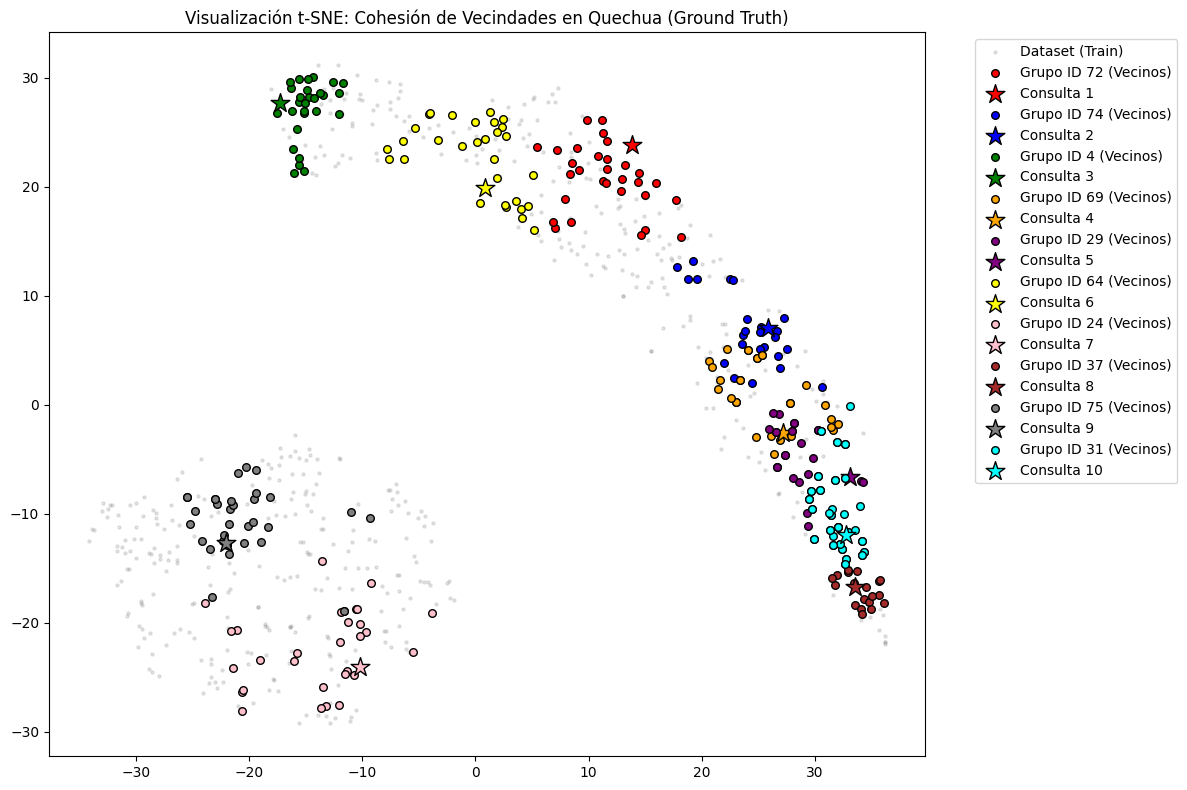

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

# 1. CARGAR DATOS (Asegúrate de tener los embeddings originales a la mano)
# Necesitamos un array con TODOS los embeddings para que la reducción sea consistente
# Supongamos que 'X_total' es la unión de embeddings de train y test
X_train = np.vstack(pd.read_parquet("823_dataset/train.parquet")["emb"].tolist())
X_test = np.vstack(pd.read_parquet("823_dataset/test.parquet")["emb"].tolist())
X_combined = np.vstack([X_train, X_test])

X_pca = PCA(n_components=50).fit_transform(X_combined)

# 2. REDUCCIÓN DE DIMENSIONALIDAD (t-SNE es mejor para esto)
print("Calculando t-SNE (esto puede tardar unos minutos)...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
coords = tsne.fit_transform(X_pca) #X_combined
print(f"Divergencia Kullback-Leibler (KL) final: {tsne.kl_divergence_:.4f}")

# Separar las coordenadas para facilitar el acceso
coords_train = coords[:len(X_train)]
coords_test = coords[len(X_train):]

# 3. SELECCIÓN DE GRUPOS (5 IDs aleatorios del test)
df_neighbors = pd.read_parquet("823_dataset/neighbors.parquet")
sample_queries = df_neighbors.sample(10, random_state=123)
colores = ['red', 'blue', 'green', 'orange', 'purple','yellow', 'pink', 'brown', 'gray', 'cyan']

# 4. GRAFICAR
plt.figure(figsize=(12, 8))

# Fondo: Todos los puntos en gris suave
plt.scatter(coords_train[:, 0], coords_train[:, 1], c='grey', alpha=0.2, s=5, label='Dataset (Train)')

# Dibujar cada grupo
for i, (idx, row) in enumerate(sample_queries.iterrows()):
    query_id = int(row['id'])
    neighbor_ids = row['neighbors_id'][:30] # Tomamos los top 10 vecinos
    color = colores[i]
    
    # Graficar los vecinos (del train)
    n_coords = coords_train[neighbor_ids]
    plt.scatter(n_coords[:, 0], n_coords[:, 1], c=color, s=30, edgecolors='black', label=f'Grupo ID {query_id} (Vecinos)')
    
    # Graficar la consulta (del test) con una estrella
    q_coord = coords_test[query_id]
    plt.scatter(q_coord[0], q_coord[1], c=color, s=200, marker='*', edgecolors='black', label=f'Consulta {i+1}')

plt.title("Visualización t-SNE: Cohesión de Vecindades en Quechua (Ground Truth)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [7]:
from sklearn.metrics import silhouette_score
from sklearn.manifold import trustworthiness
from scipy.spatial.distance import euclidean

# --- A. Trustworthiness ---
# Evalúa la fidelidad de la reducción (usamos una muestra si el dataset es gigante)
sample_size = min(5000, len(X_combined))
tw = trustworthiness(X_combined[:sample_size], coords[:sample_size], n_neighbors=10)
print(f"Confianza de la reducción (Trustworthiness): {tw:.4f}")


Confianza de la reducción (Trustworthiness): 0.9821


In [8]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from scipy.stats import spearmanr
from scipy.spatial.distance import cdist

# --- 1. REDUCCIÓN E INICIALIZACIÓN ROBUSTA (Consenso actual) ---
print("Aplicando PCA previo para reducir ruido de 1024D a 50D...")
pca = PCA(n_components=50, random_state=42)
X_pca = pca.fit_transform(X_combined)

print("Calculando t-SNE con inicialización PCA y perplejidad optimizada...")
# Usamos init='pca' y perplexity=16 según recomendaciones de Gove y Anacker
tsne = TSNE(n_components=2, perplexity=16, init='pca', random_state=42)
coords = tsne.fit_transform(X_pca)

coords_train = coords[:len(X_train)]
coords_test = coords[len(X_train):]

# --- 2. EVALUACIÓN MEDIANTE KNN ACCURACY (Reemplaza a Silhouette) ---
# Vamos a ver si los top vecinos en 2D pertenecen al mismo "Grupo" de la consulta
group_points = []
group_labels = []

for i, (idx, row) in enumerate(sample_queries.iterrows()):
    neighbor_ids = row['neighbors_id'][:30]
    group_points.append(coords_train[neighbor_ids])
    group_labels.extend([i] * len(neighbor_ids)) # Cada grupo de vecinos tiene la etiqueta de su consulta

X_eval = np.vstack(group_points)
y_eval = np.array(group_labels)

# Evaluamos con un clasificador KNN si los puntos mantienen sus vecindades de grupo en 2D
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_eval, y_eval)
knn_acc = knn.score(X_eval, y_eval)

print(f"Precisión de Vecindad KNN (Clústeres locales en 2D): {knn_acc:.4f}")

# --- 3. CORRELACIÓN DE RANGOS DE SPEARMAN (Reemplaza al Ratio Euclidiano) ---
# Mide si el orden de cercanía (1º, 2º, 3º...) se preservó del espacio 50D al 2D
dist_orig_sample = cdist(X_pca[:500], X_pca[:500]).flatten()
dist_tsne_sample = cdist(coords[:500], coords[:500]).flatten()

spearman_rho, _ = spearmanr(dist_orig_sample, dist_tsne_sample)
print(f"Correlación de Rangos de Spearman (Fidelidad Global/Local): {spearman_rho:.4f}")

Aplicando PCA previo para reducir ruido de 1024D a 50D...
Calculando t-SNE con inicialización PCA y perplejidad optimizada...
Precisión de Vecindad KNN (Clústeres locales en 2D): 0.8567
Correlación de Rangos de Spearman (Fidelidad Global/Local): 0.7393


TABLAS DE RESULTADOS DEL BENCHMARK

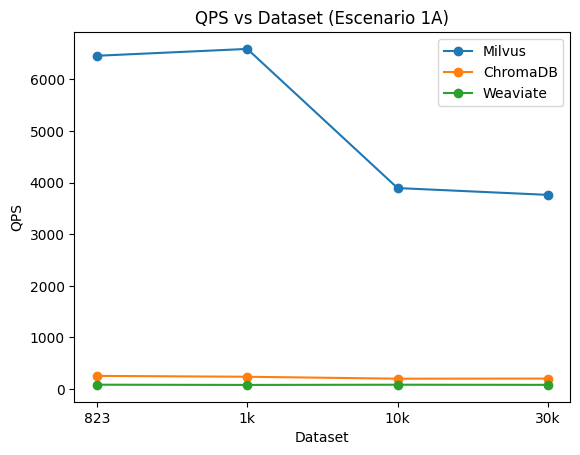

In [5]:
import matplotlib.pyplot as plt

datasets = ["823", "1k", "10k", "30k"]

milvus = [6455.11, 6587.56, 3893.40, 3761.35]
chroma = [256.38, 239.44, 202.08, 204.25]
weaviate = [85.63, 81.30, 85.20, 82.63]

plt.figure()

plt.plot(datasets, milvus, marker='o', label='Milvus')
plt.plot(datasets, chroma, marker='o', label='ChromaDB')
plt.plot(datasets, weaviate, marker='o', label='Weaviate')

plt.xlabel("Dataset")
plt.ylabel("QPS")
plt.title("QPS vs Dataset (Escenario 1A)")
plt.legend()

plt.show()

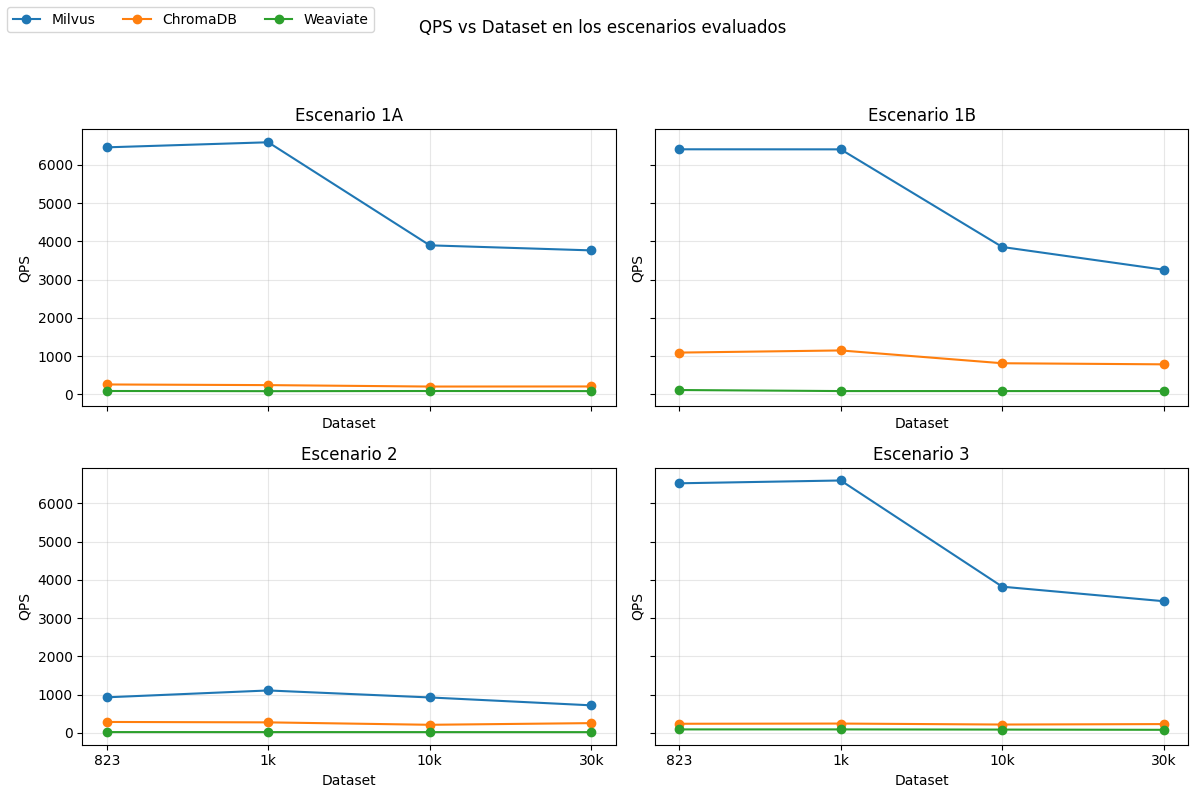

In [8]:
import matplotlib.pyplot as plt

datasets = ["823", "1k", "10k", "30k"]

# Escenario 1A
milvus_1a = [6455.11, 6587.56, 3893.40, 3761.35]
chroma_1a = [256.38, 239.44, 202.08, 204.25]
weaviate_1a = [85.63, 81.30, 85.20, 82.63]

# Escenario 1B
milvus_1b = [6403.99, 6402.38, 3850.22, 3255.17]
chroma_1b = [1089.66, 1145.81, 811.17, 782.60]
weaviate_1b = [111.08, 83.95, 83.56, 84.05]

# Escenario 2
milvus_2 = [928.77, 1107.95, 925.33, 719.03]
chroma_2 = [284.64, 273.98, 210.55, 254.20]
weaviate_2 = [19.95, 19.72, 19.24, 18.42]

# Escenario 3
milvus_3 = [6523.48, 6596.87, 3820.54, 3440.80]
chroma_3 = [237.37, 242.71, 217.14, 229.02]
weaviate_3 = [89.99, 90.05, 85.25, 79.31]

fig, axs = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)

scenarios = [
    ("Escenario 1A", milvus_1a, chroma_1a, weaviate_1a),
    ("Escenario 1B", milvus_1b, chroma_1b, weaviate_1b),
    ("Escenario 2", milvus_2, chroma_2, weaviate_2),
    ("Escenario 3", milvus_3, chroma_3, weaviate_3),
]

for ax, (title, milvus, chroma, weaviate) in zip(axs.flat, scenarios):
    ax.plot(datasets, milvus, marker='o', label='Milvus')
    ax.plot(datasets, chroma, marker='o', label='ChromaDB')
    ax.plot(datasets, weaviate, marker='o', label='Weaviate')
    ax.set_title(title)
    ax.set_xlabel("Dataset")
    ax.set_ylabel("QPS")
    ax.grid(True, alpha=0.3)
    #ax.set_yscale('log')  # recomendable por la diferencia de magnitudes

handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper left', ncol=3)

fig.suptitle("QPS vs Dataset en los escenarios evaluados", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

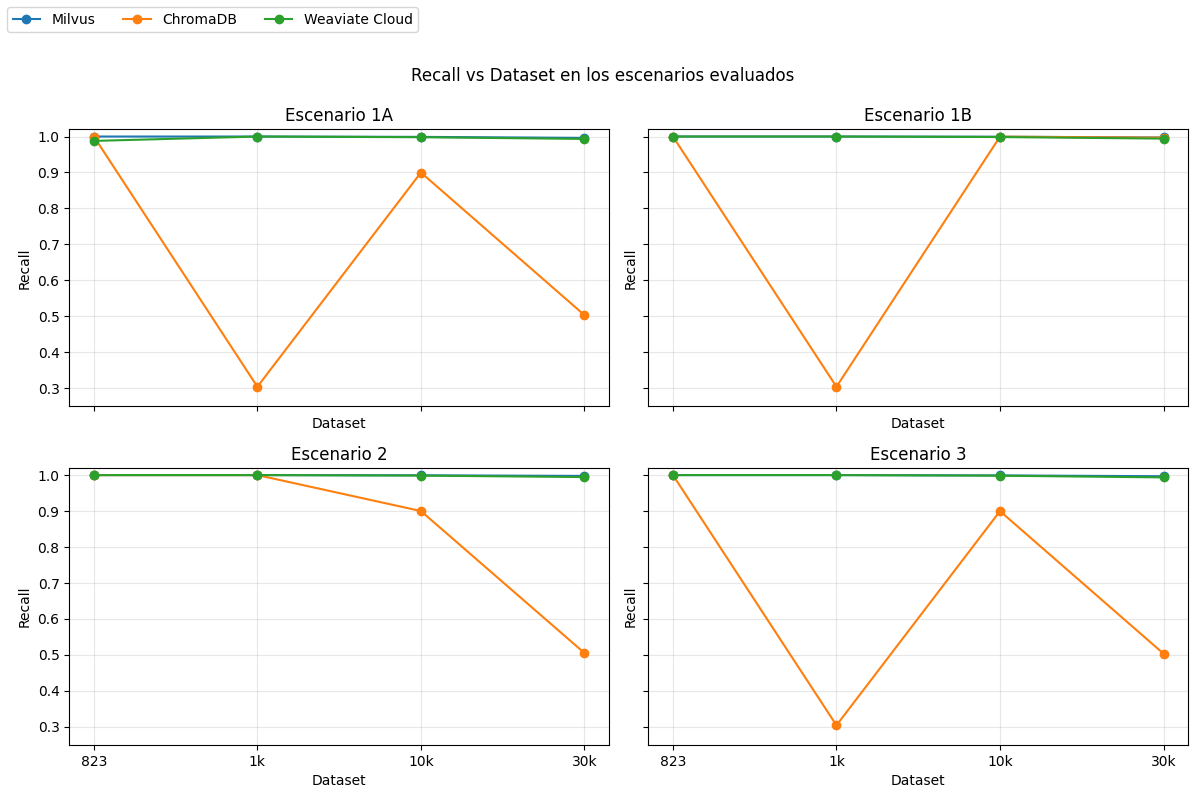

In [15]:
import matplotlib.pyplot as plt

# Eje X como categorías discretas
datasets = ["823", "1k", "10k", "30k"]

# -------------------------
# ESCENARIO 1A
# -------------------------
milvus_1a = [1.0000, 1.0000, 0.9990, 0.9962]
chroma_1a = [1.0000, 0.3040, 0.8999, 0.5032]
weaviate_1a = [0.9878, 1.0000, 0.9981, 0.9933]

# -------------------------
# ESCENARIO 1B
# -------------------------
milvus_1b = [1.0000, 1.0000, 0.9995, 0.9973]
chroma_1b = [1.0000, 0.3040, 0.9996, 0.9968]
weaviate_1b = [1.0000, 1.0000, 0.9986, 0.9942]

# -------------------------
# ESCENARIO 2
# -------------------------
milvus_2 = [1.0000, 1.0000, 0.9994, 0.9977]
chroma_2 = [1.0000, 1.0000, 0.9000, 0.5051]
weaviate_2 = [1.0000, 1.0000, 0.9986, 0.9945]

# -------------------------
# ESCENARIO 3
# -------------------------
milvus_3 = [1.0000, 1.0000, 0.9991, 0.9968]
chroma_3 = [1.0000, 0.3040, 0.8998, 0.5033]
weaviate_3 = [1.0000, 1.0000, 0.9983, 0.9936]

fig, axs = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)

scenarios = [
    ("Escenario 1A", milvus_1a, chroma_1a, weaviate_1a),
    ("Escenario 1B", milvus_1b, chroma_1b, weaviate_1b),
    ("Escenario 2", milvus_2, chroma_2, weaviate_2),
    ("Escenario 3", milvus_3, chroma_3, weaviate_3),
]

for ax, (title, milvus, chroma, weaviate) in zip(axs.flat, scenarios):
    ax.plot(datasets, milvus, marker='o', label='Milvus')
    ax.plot(datasets, chroma, marker='o', label='ChromaDB')
    ax.plot(datasets, weaviate, marker='o', label='Weaviate Cloud')
    ax.set_title(title)
    ax.set_xlabel("Dataset")
    ax.set_ylabel("Recall")
    ax.set_ylim(0.25, 1.02)
    ax.grid(True, alpha=0.3)

handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper left', ncol=3)

fig.suptitle("Recall vs Dataset en los escenarios evaluados", y=0.92)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

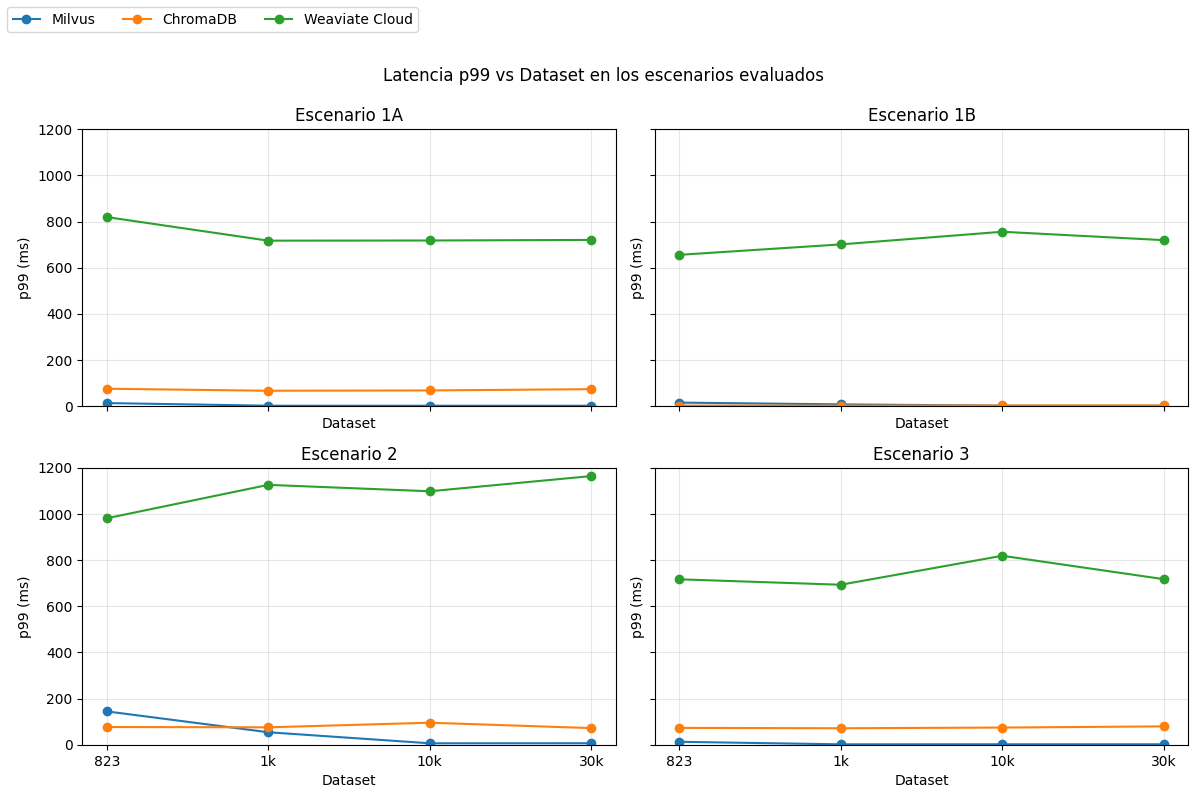

In [17]:
import matplotlib.pyplot as plt

datasets = ["823", "1k", "10k", "30k"]

# -------------------------
# ESCENARIO 1A
# -------------------------
milvus_1a = [13.4, 1.9, 1.9, 1.8]
chroma_1a = [75.5, 66.8, 68.1, 73.7]
weaviate_1a = [819.7, 717.4, 718.1, 720.6]

# -------------------------
# ESCENARIO 1B
# -------------------------
milvus_1b = [15.4, 7.7, 2.1, 1.9]
chroma_1b = [2.5, 2.5, 2.9, 3.1]
weaviate_1b = [655.9, 701.2, 756.0, 719.6]

# -------------------------
# ESCENARIO 2
# -------------------------
milvus_2 = [144.6, 54.1, 6.2, 6.4]
chroma_2 = [76.9, 75.4, 95.4, 72.0]
weaviate_2 = [981.6, 1126.5, 1098.7, 1164.6]

# -------------------------
# ESCENARIO 3
# -------------------------
milvus_3 = [12.7, 1.7, 1.9, 1.9]
chroma_3 = [73.0, 71.4, 74.4, 79.5]
weaviate_3 = [717.1, 693.5, 819.1, 717.6]

fig, axs = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)

scenarios = [
    ("Escenario 1A", milvus_1a, chroma_1a, weaviate_1a),
    ("Escenario 1B", milvus_1b, chroma_1b, weaviate_1b),
    ("Escenario 2", milvus_2, chroma_2, weaviate_2),
    ("Escenario 3", milvus_3, chroma_3, weaviate_3),
]

for ax, (title, milvus, chroma, weaviate) in zip(axs.flat, scenarios):
    ax.plot(datasets, milvus, marker='o', label='Milvus')
    ax.plot(datasets, chroma, marker='o', label='ChromaDB')
    ax.plot(datasets, weaviate, marker='o', label='Weaviate Cloud')
    ax.set_title(title)
    ax.set_xlabel("Dataset")
    ax.set_ylabel("p99 (ms)")
    ax.set_ylim(0, 1200)
    ax.grid(True, alpha=0.3)

handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper left', ncol=3)

fig.suptitle("Latencia p99 vs Dataset en los escenarios evaluados", y=0.92)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

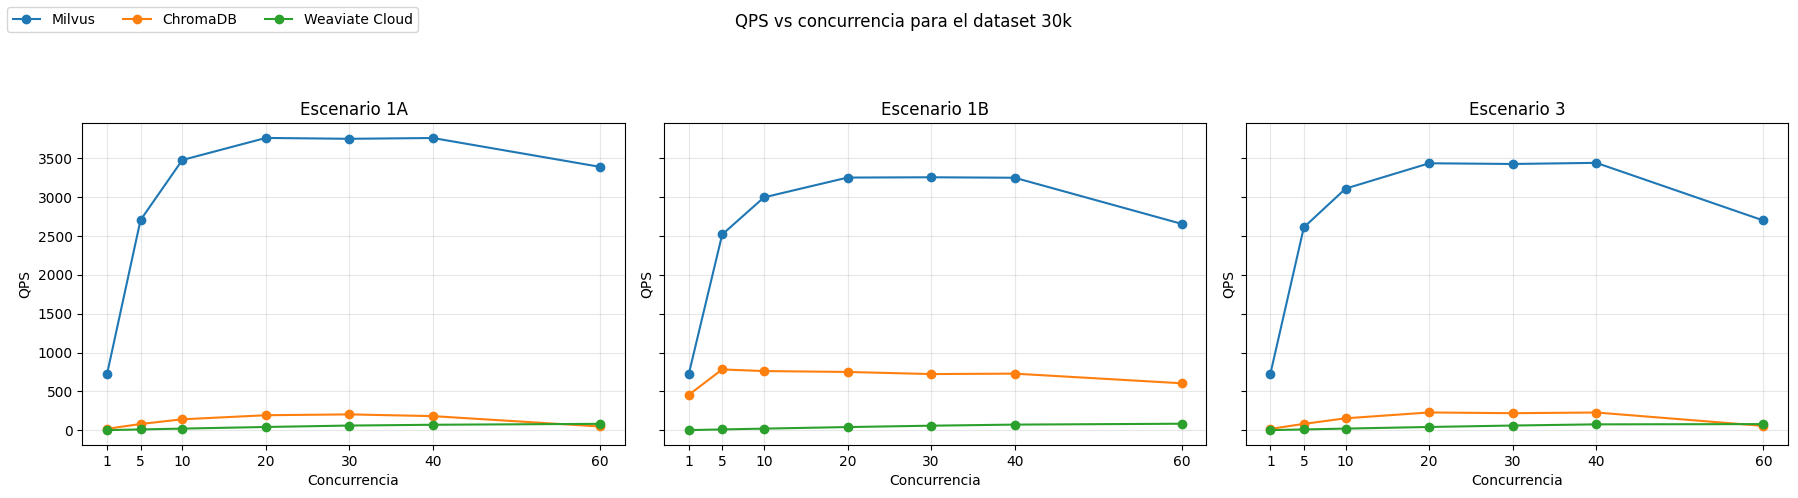

In [ ]:
import matplotlib.pyplot as plt

concurrency = [1, 5, 10, 20, 30, 40, 60]

# =========================
# ESCENARIO 1A
# =========================
milvus_1a_qps   = [727.576, 2704.3026, 3477.4727, 3761.3537, 3750.4033, 3760.413, 3389.2073]
chroma_1a_qps   = [18.9846, 80.3626, 140.9596, 193.3605, 204.2523, 181.8715, 48.5259]
weaviate_1a_qps = [1.9208, 10.5662, 21.4017, 42.2388, 60.5267, 70.7156, 82.6305]

# =========================
# ESCENARIO 1B
# =========================
milvus_1b_qps   = [722.894, 2519.1282, 2996.7124, 3251.4355, 3255.1673, 3249.3439, 2655.7738]
chroma_1b_qps   = [455.7724, 782.6019, 761.5828, 750.3404, 723.0394, 728.6419, 604.5453]
weaviate_1b_qps = [1.8806, 10.7572, 21.1701, 41.0728, 58.7881, 72.7796, 84.0494]

# =========================
# ESCENARIO 2
# =========================
milvus_2_qps   = [729.5297, 2611.3765, 3109.7701, 3435.4363, 3426.3836, 3440.7982, 2699.0657]
chroma_2_qps   = [17.6118, 82.2768, 153.9101, 229.0152, 219.6065, 228.4936, 56.1218]
weaviate_2_qps = [1.927, 10.5292, 21.5382, 42.2437, 60.7764, 76.0525, 79.3062]

# =========================
# ESCENARIO 3
# =========================
milvus_3_qps   = [729.5297, 2611.3765, 3109.7701, 3435.4363, 3426.3836, 3440.7982, 2699.0657]
chroma_3_qps   = [17.6118, 82.2768, 153.9101, 229.0152, 219.6065, 228.4936, 56.1218]
weaviate_3_qps = [1.927, 10.5292, 21.5382, 42.2437, 60.7764, 76.0525, 79.3062]

fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

scenarios = [
    ("Escenario 1A", milvus_1a_qps, chroma_1a_qps, weaviate_1a_qps),
    ("Escenario 1B", milvus_1b_qps, chroma_1b_qps, weaviate_1b_qps),
    ("Escenario 3",  milvus_3_qps,  chroma_3_qps,  weaviate_3_qps),
]

for ax, (title, milvus, chroma, weaviate) in zip(axs, scenarios):
    ax.plot(concurrency, milvus, marker='o', label='Milvus')
    ax.plot(concurrency, chroma, marker='o', label='ChromaDB')
    ax.plot(concurrency, weaviate, marker='o', label='Weaviate Cloud')
    ax.set_title(title)
    ax.set_xlabel("Concurrencia")
    ax.set_ylabel("QPS")
    ax.set_xticks(concurrency)
    ax.grid(True, alpha=0.3)

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper left', ncol=3)

fig.suptitle("QPS vs concurrencia para el dataset 30k", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()

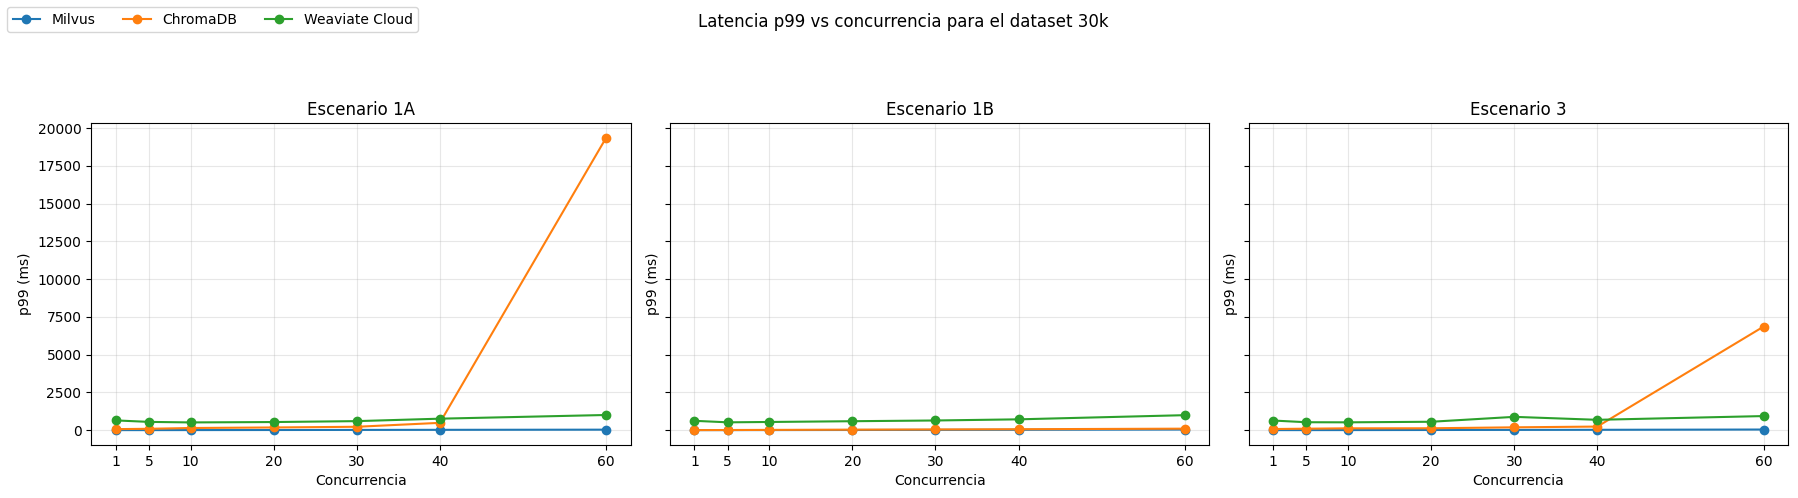

In [5]:
import matplotlib.pyplot as plt

concurrency = [1, 5, 10, 20, 30, 40, 60]

# =========================
# ESCENARIO 1A (segundos -> ms)
# =========================
milvus_1a_p99   = [x * 1000 for x in [0.0018338701198808845, 0.0026105505507439367, 0.004342084117233753, 0.009150652494281531, 0.01501679176464677, 0.020576461637392667, 0.03165337552549317]]
chroma_1a_p99   = [x * 1000 for x in [0.06661639300291428, 0.08946638296125457, 0.1411987480061361, 0.17706776798702753, 0.2225281100126449, 0.4827043240261262, 19.33942290501249]]
weaviate_1a_p99 = [x * 1000 for x in [0.6446903539821504, 0.5459002883639185, 0.5111049533588812, 0.5357852824963629, 0.5967483180784621, 0.7584450510796156, 1.0029590363684109]]

# =========================
# ESCENARIO 1B (segundos -> ms)
# =========================
milvus_1b_p99   = [x * 1000 for x in [0.0018387131858617067, 0.0028757715923711648, 0.00492956276517361, 0.01060208082431928, 0.01732386605814098, 0.023962450893595808, 0.04030958970542997]]
chroma_1b_p99   = [x * 1000 for x in [0.0028704459429718552, 0.00784203411079943, 0.016496343638282243, 0.030806540134362848, 0.04541132189333439, 0.06078592834062874, 0.09791037362068909]]
weaviate_1b_p99 = [x * 1000 for x in [0.6173567251721397, 0.5172654872480779, 0.5404732541926205, 0.5909956214018165, 0.6392593986331486, 0.7151490606088192, 0.9908869016706012]]

# =========================
# ESCENARIO 3 (segundos -> ms)
# =========================
milvus_3_p99   = [x * 1000 for x in [0.0018421386252157384, 0.002773418202996252, 0.004696036314126107, 0.009954848494380717, 0.016386185772717, 0.022488196101039647, 0.04035271666944012]]
chroma_3_p99   = [x * 1000 for x in [0.0742424499912886, 0.09625153699365908, 0.1208215639938135, 0.12365065998630594, 0.18592865698970854, 0.2358967900287826, 6.852533442006737]]
weaviate_3_p99 = [x * 1000 for x in [0.6355255739972923, 0.523543070605956, 0.5169777966220863, 0.554423500557896, 0.8795257940609028, 0.6834384926082566, 0.9314468429121189]]

fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

scenarios = [
    ("Escenario 1A", milvus_1a_p99, chroma_1a_p99, weaviate_1a_p99),
    ("Escenario 1B", milvus_1b_p99, chroma_1b_p99, weaviate_1b_p99),
    ("Escenario 3",  milvus_3_p99,  chroma_3_p99,  weaviate_3_p99),
]

for ax, (title, milvus, chroma, weaviate) in zip(axs, scenarios):
    ax.plot(concurrency, milvus, marker='o', label='Milvus')
    ax.plot(concurrency, chroma, marker='o', label='ChromaDB')
    ax.plot(concurrency, weaviate, marker='o', label='Weaviate Cloud')
    ax.set_title(title)
    ax.set_xlabel("Concurrencia")
    ax.set_ylabel("p99 (ms)")
    ax.set_xticks(concurrency)
    ax.grid(True, alpha=0.3)

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper left', ncol=3)

fig.suptitle("Latencia p99 vs concurrencia para el dataset 30k", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()

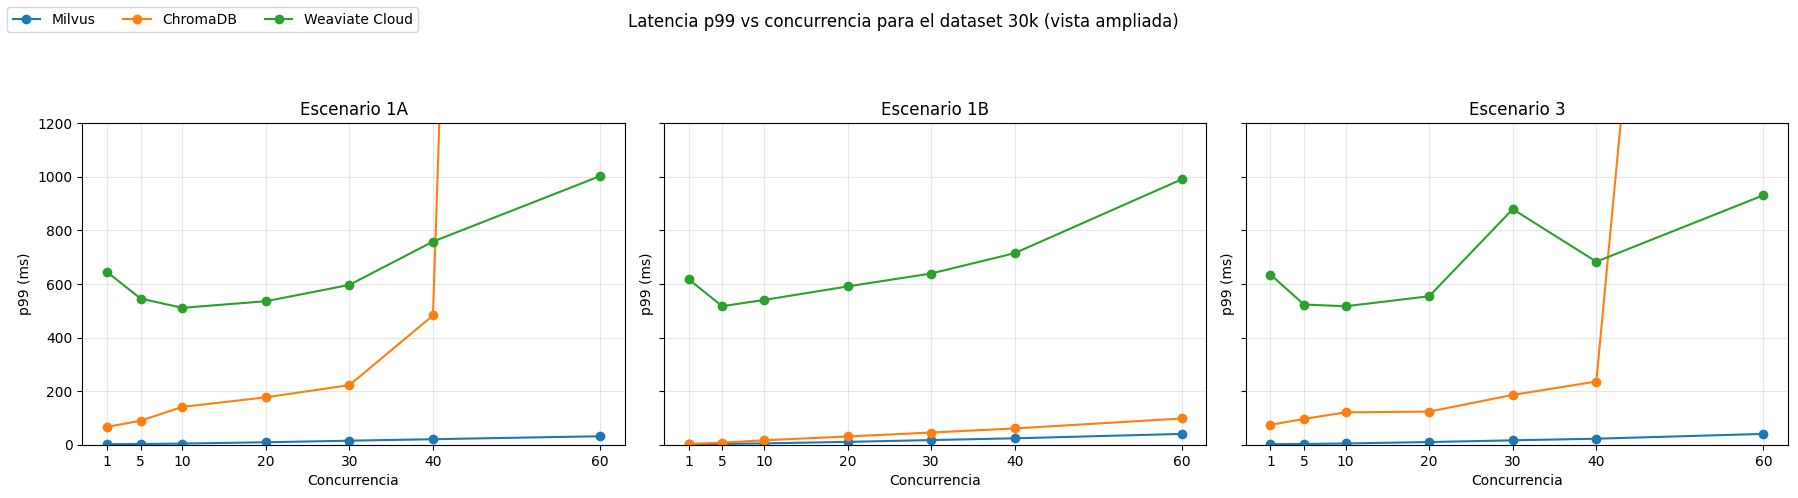

In [6]:
import matplotlib.pyplot as plt

concurrency = [1, 5, 10, 20, 30, 40, 60]

fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

scenarios = [
    ("Escenario 1A", milvus_1a_p99, chroma_1a_p99, weaviate_1a_p99),
    ("Escenario 1B", milvus_1b_p99, chroma_1b_p99, weaviate_1b_p99),
    ("Escenario 3",  milvus_3_p99,  chroma_3_p99,  weaviate_3_p99),
]

for ax, (title, milvus, chroma, weaviate) in zip(axs, scenarios):
    ax.plot(concurrency, milvus, marker='o', label='Milvus')
    ax.plot(concurrency, chroma, marker='o', label='ChromaDB')
    ax.plot(concurrency, weaviate, marker='o', label='Weaviate Cloud')
    ax.set_title(title)
    ax.set_xlabel("Concurrencia")
    ax.set_ylabel("p99 (ms)")
    ax.set_xticks(concurrency)
    ax.set_ylim(0, 1200)
    ax.grid(True, alpha=0.3)

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper left', ncol=3)

fig.suptitle("Latencia p99 vs concurrencia para el dataset 30k (vista ampliada)", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()